# **Metabolic study preprocessing and visualization**

Prepare the study exports and inspect the existing data-quality plots. 

- `mental_physical_pain.csv` and `nutreval.csv` feed, run [Univariate_Associations.ipynb](Univariate_Associations.ipynb).
- `basic_info.csv`, `meds.csv`, `week_sleep_functionality.csv`, `deviance_meals.csv`, the medication-field extract, and the laboratory missingness workbook reproduce the other preprocessing exports.
- The questionnaire indicators and nutrient-color proportions are intermediate DataFrames. The original notebook computed them in memory.

The Python dependencies are `pandas`, `numpy`, and `openpyxl` for the exports. The optional figures also use `matplotlib`, `seaborn`, and `scikit-learn`.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

DATA_DIR = Path("./../data")
PROCESSED_DIR = Path("./../processed-11-2026")
PROCESSED_DIR.mkdir(exist_ok=True)

DEMOGRAPHICS_AND_SURVEY_EXCLUSIONS = [1, 3, 16, 19, 27]
SCORE_AND_NUTREVAL_EXCLUSIONS = [1, 3, 27]
MAKE_QA_PLOTS = True


def read_event(filename, event):
    """Read one event from a study export and index rows by Study ID."""
    data = pd.read_csv(DATA_DIR / filename)
    return data.loc[data["Event Name"].eq(event)].set_index("Study ID")

## Baseline demographics and medications

Select the enrollment event, apply the recorded weight correction, and convert waist and hip values for the specified participants from inches to centimeters. The medication export drops Study ID 27 and fills blank entries with zero, following the original notebook. `Meds_Analysis.csv` contains the original enrollment columns whose names start with `Medication`.

In [3]:
enrollment = read_event("Demographics.csv", "Baseline visit-enrollment")
enrollment = enrollment.drop(DEMOGRAPHICS_AND_SURVEY_EXCLUSIONS)
basic_info = enrollment.copy()

basic_info.loc[22, "Weight (lbs)"] = 180
circumference_columns = ["Waist circumference (cm)", "Hip circumference (cm)"]
basic_info[circumference_columns] = basic_info[circumference_columns].astype(float)
basic_info.loc[[13, 14, 21, 33], circumference_columns] *= 2.54

demographics_columns = ["Age (years)", "Gender", "Height (in)", "Weight (lbs)"]
demographics_columns += circumference_columns
basic_info[demographics_columns].to_csv(PROCESSED_DIR / "basic_info.csv")

meds = pd.read_csv(DATA_DIR / "Meds.csv", index_col=0).drop(27).fillna(0)
meds.to_csv(PROCESSED_DIR / "meds.csv")

medication_columns = basic_info.columns[basic_info.columns.str.startswith("Medication")]
basic_info[medication_columns].to_csv(PROCESSED_DIR / "Meds_Analysis.csv")

## Day 1 questionnaire scores

Keep the Day 1 visit and apply the four recorded SF-36 and summary-score corrections. Some source column names end with a space. Keep those names so the exported CSV has the same fields as the original.

In [4]:
scores = read_event("BaselineScores.csv", "Day 1 visit")
scores = scores.drop(SCORE_AND_NUTREVAL_EXCLUSIONS)
scores = scores.drop(columns=["Event Name", "Complete?"])

scores.loc[25, "SF-36 Emotional Well-Being Score: "] = 3.2
scores.loc[25, "Mental health summary"] = 5.18
scores.loc[30, "SF-36 Physical Functioning Score: "] = 2.44
scores.loc[30, "Physical health summary"] = 13.11

scores.to_csv(PROCESSED_DIR / "mental_physical_pain.csv")

## NutrEval measurements

Normalize the existing detection-limit and missingness labels and export their counts. The workbook counts `<dl`, `nr`, and null entries before the recorded corrections, as in the original. Strings such as `>14.8` remain available in `nutreval` for inspection and become missing in `nutreval_numeric`. The original direct float cast failed on these strings. The numeric export uses the same numeric-only rule MK used to select observations for regression.

In [5]:
nutreval = read_event("Nutreval.csv", "Nutreval data")
nutreval = nutreval.drop(SCORE_AND_NUTREVAL_EXCLUSIONS)
nutreval = nutreval.drop(columns=["Event Name", "Complete?"])
nutreval = nutreval.replace({
    "<DL": "<dl",
    "<Dl": "<dl",
    "Not reported ": "nr",
    "Not reported": "nr",
    "NR": "nr",
    "Not performed ": np.nan,
})

missing_counts = pd.DataFrame({
    "<dl": nutreval.eq("<dl").sum(),
    "NaN": nutreval.isna().sum(),
    "NR": nutreval.eq("nr").sum(),
})
missing_counts["Missing"] = missing_counts.sum(axis=1)
missing_counts = missing_counts.loc[missing_counts["Missing"].gt(0)]
missing_counts.index.name = "Component"
missing_counts.to_excel(PROCESSED_DIR / "components_missing_vals.xlsx")

# Keep corrections scoped to the fields and Study IDs in Visualization.ipynb.
for column, original, corrected in [
    ("Arginine", "8.08.4", 8.4),
    ("Histidine", "7..7", 7.7),
    ("Glutathione", "1,066", 1066),
]:
    nutreval.loc[nutreval[column].eq(original), column] = corrected

potassium_ids = [2, 4, 5, 7, 8, 9, 10]
nutreval.loc[potassium_ids, "Potassium"] = [2750, 2455, 3106, 2430, 3516, 2124, 2452]

nutreval_numeric = nutreval.apply(pd.to_numeric, errors="coerce")
nutreval_numeric.to_csv(PROCESSED_DIR / "nutreval.csv")

## DePaul symptom indicators

Read the same positions from `DayVisit.csv`. Each symptom must score at least 2 on both frequency and severity. The domain indicators below retain the original item ranges and the original minimum number of qualifying symptoms. The fatigue item and the SF-36 rule are separate indicators. These calculations are the partial questionnaire scoring from the original notebook.

In [6]:
day_visit = pd.read_csv(DATA_DIR / "DayVisit.csv", index_col="Study ID")


def parse_questionnaire_value(value):
    if isinstance(value, str) and "=" in value:
        return int(value.split("=", 1)[0])
    return value


questionnaire = day_visit.iloc[:, 655:817].apply(
    lambda column: column.map(parse_questionnaire_value)
)


def qualifying_symptoms(positions):
    """Use the two fields immediately after each symptom label."""
    return pd.DataFrame({
        questionnaire.columns[position]: (
            questionnaire.iloc[:, position + 1].ge(2)
            & questionnaire.iloc[:, position + 2].ge(2)
        )
        for position in positions
    })


symptom_rules = {
    "Post-exertional malaise": (range(3, 18, 3), 1),
    "Sleep": (range(18, 34, 3), 1),
    "Pain": (range(36, 57, 3), 1),
    "Neurocognitive": (range(57, 94, 3), 2),
    "Autonomic": (range(96, 115, 3), 1),
    "Neuroendocrine": (range(117, 145, 3), 1),
    "Immune": (range(147, 160, 3), 1),
}
symptom_indicators = pd.DataFrame({
    "Fatigue item": qualifying_symptoms([0]).iloc[:, 0],
    **{
        domain: qualifying_symptoms(positions).sum(axis=1).ge(minimum)
        for domain, (positions, minimum) in symptom_rules.items()
    },
})

sf36_limits = pd.Series({
    "SF-36 Role-Physical Score: ": 50,
    "SF-36 Vitality Score: ": 35,
    "SF-36 Social Functioning Score: ": 62.5,
})
sf36_indicator = scores[sf36_limits.index].le(sf36_limits).sum(axis=1).ge(2)

## Optional quality-control figures

Set `MAKE_QA_PLOTS = True` in the setup cell to regenerate the available distribution, correlation, and score PCA figures from the original notebook. PCA uses the numeric score columns on their original scales. The NutrEval plot uses the numeric export and expands the grid to accommodate all markers with reported numbers.

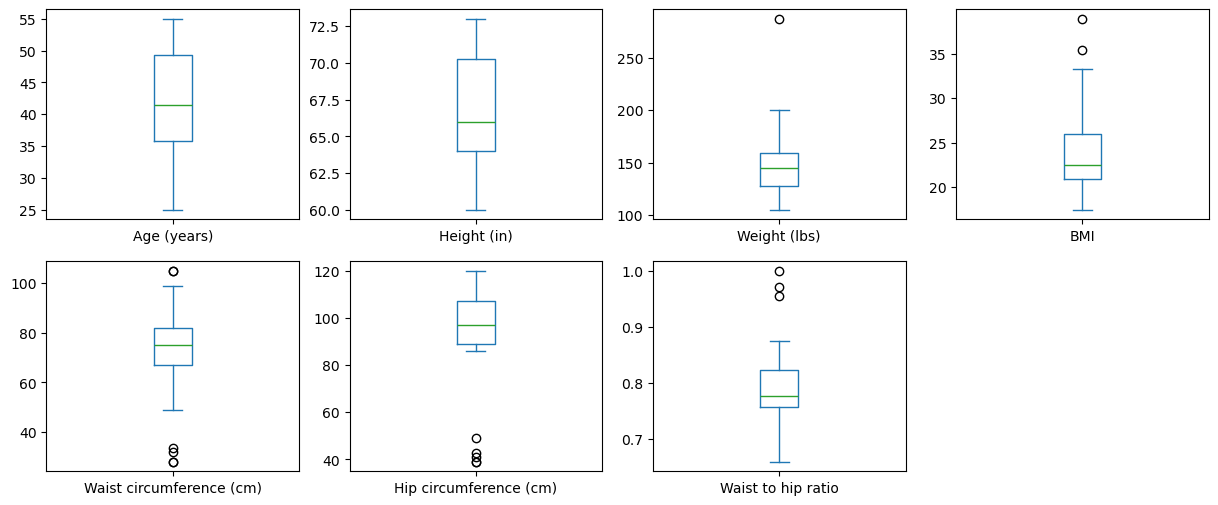

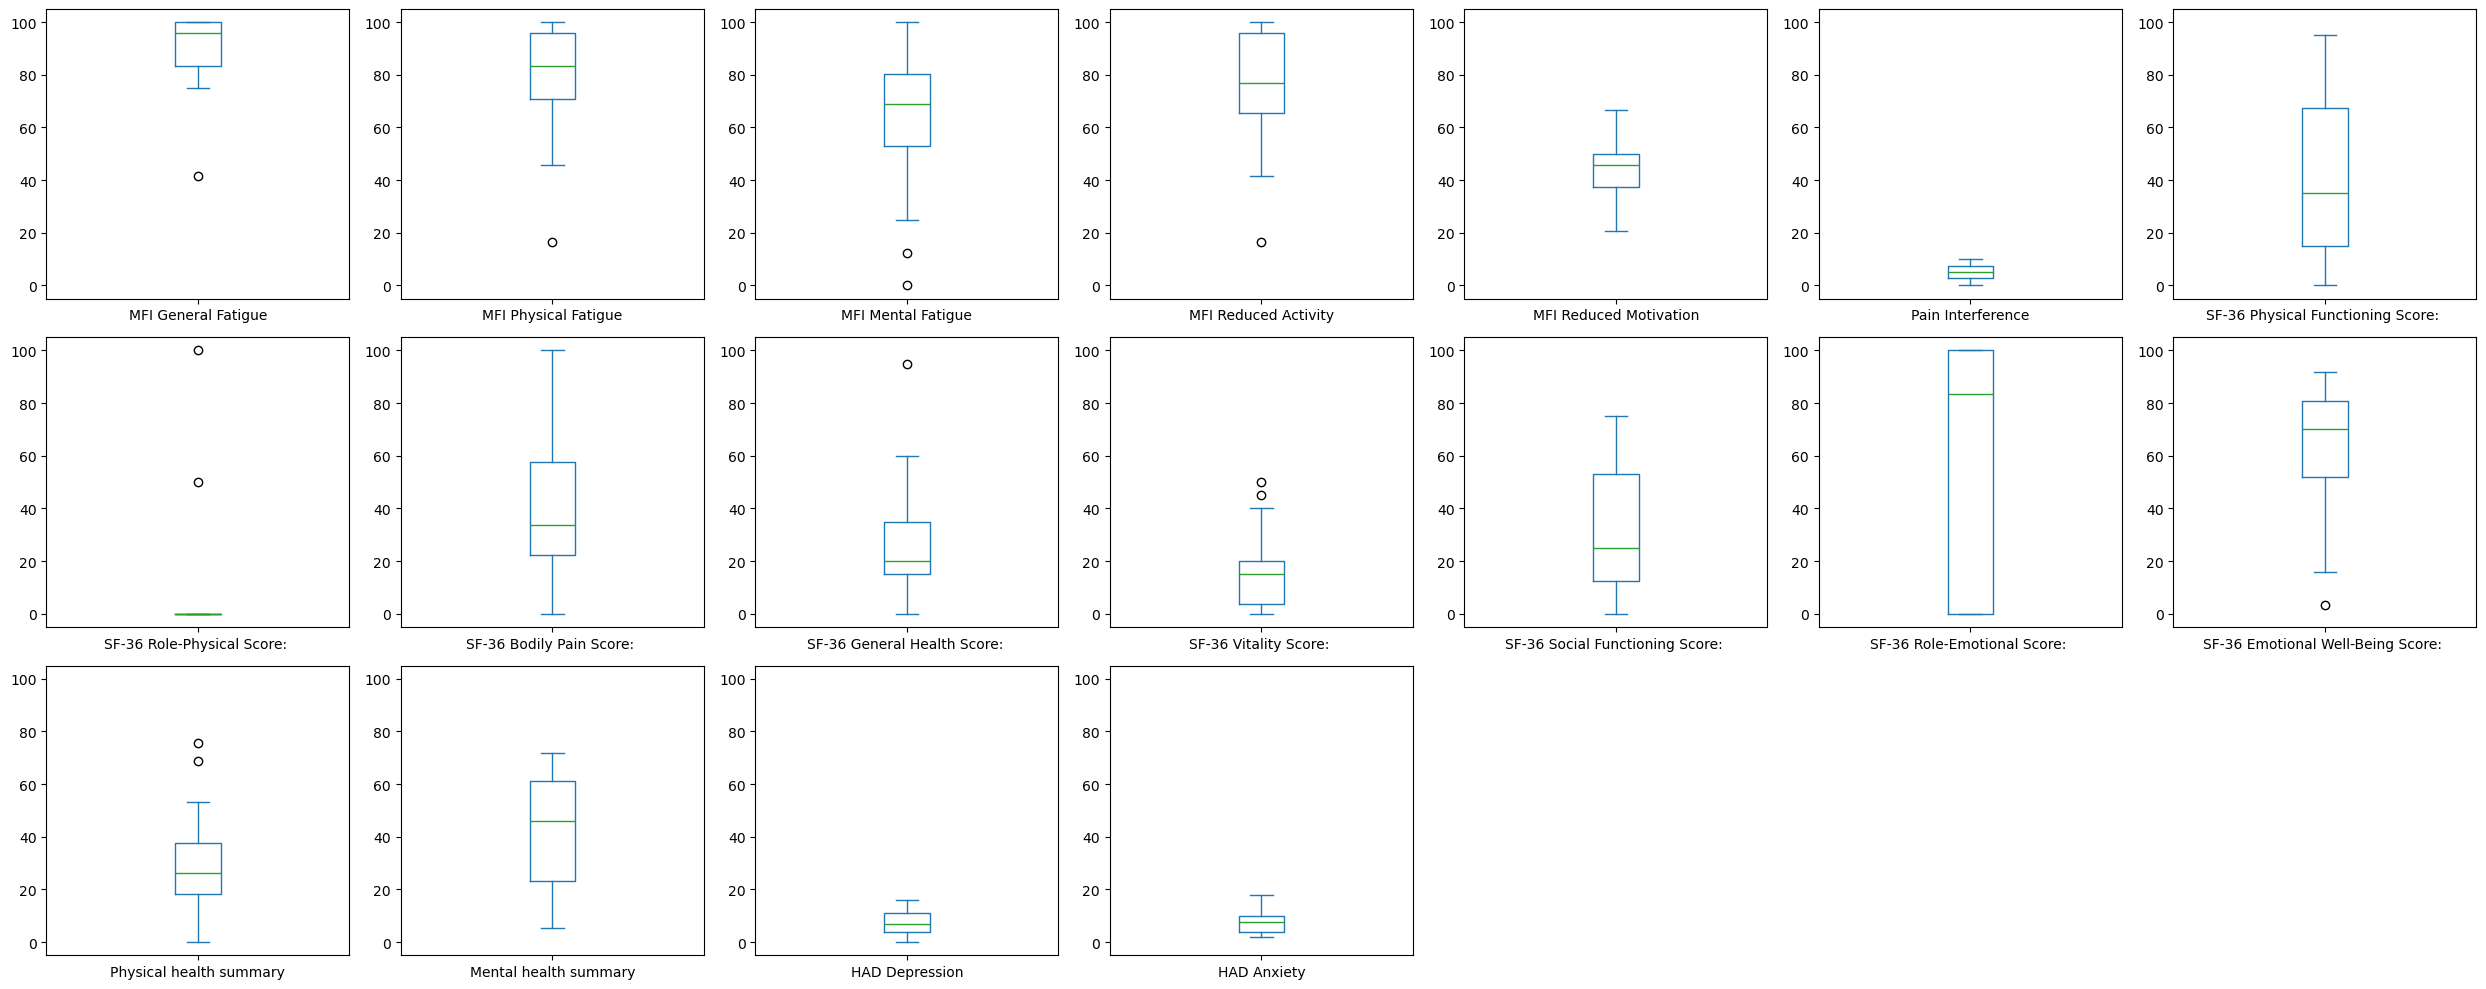

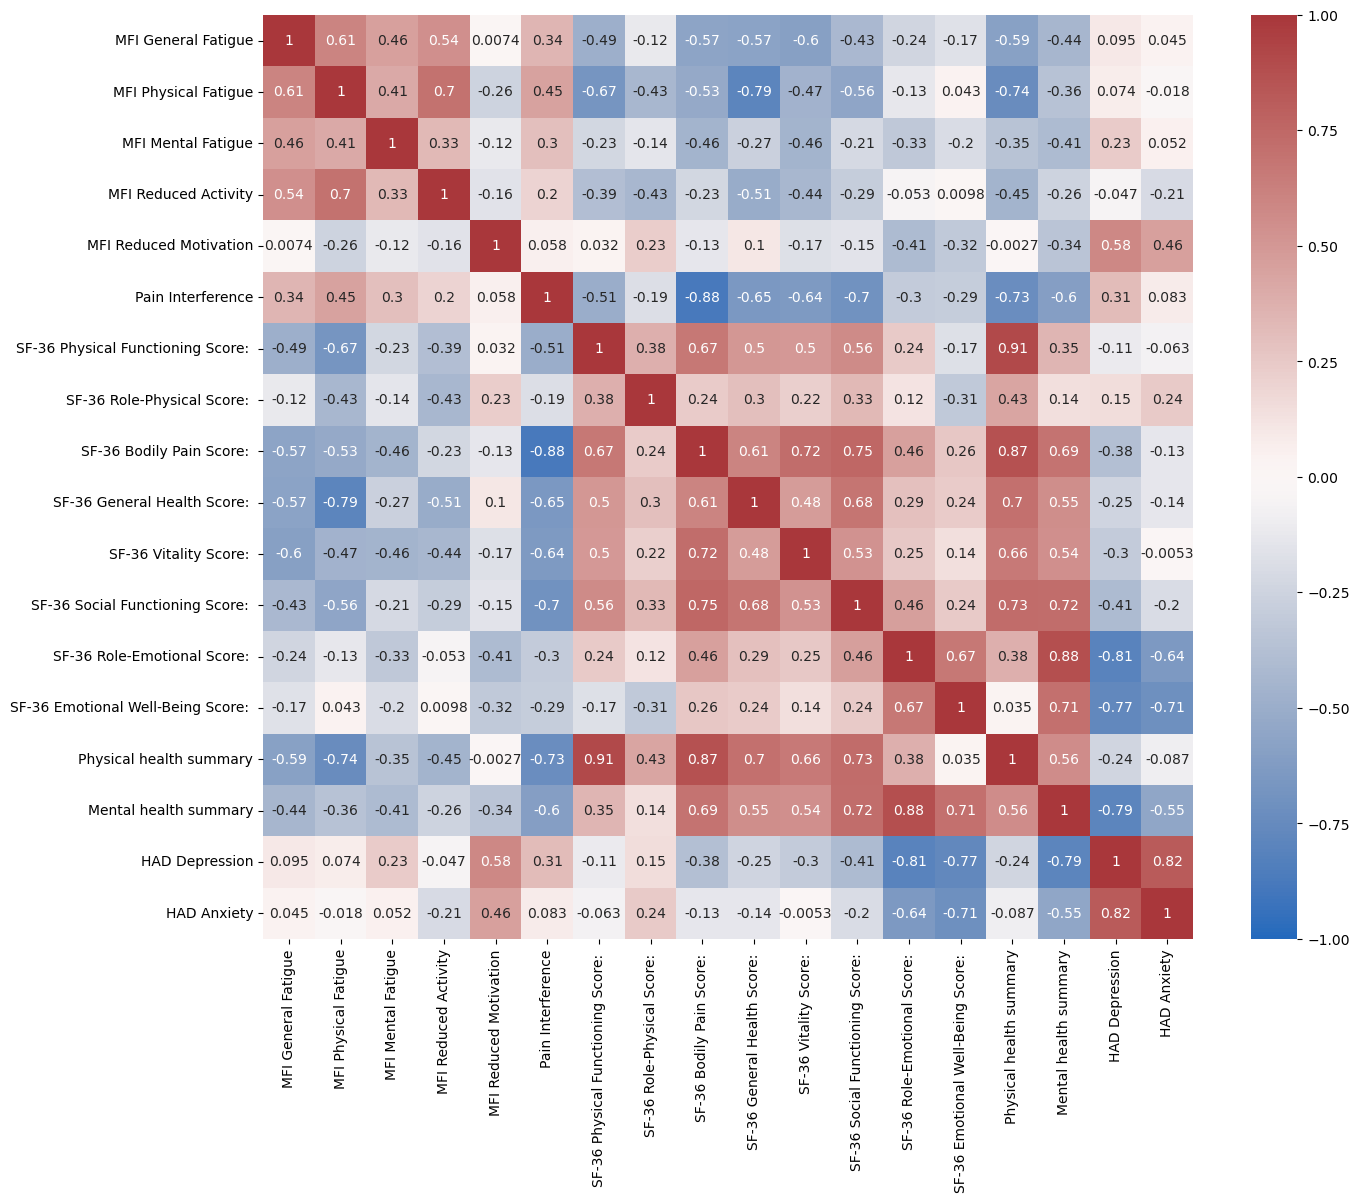

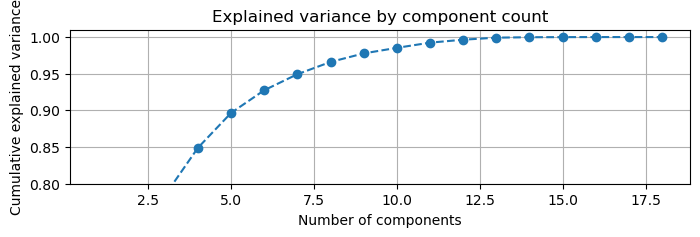

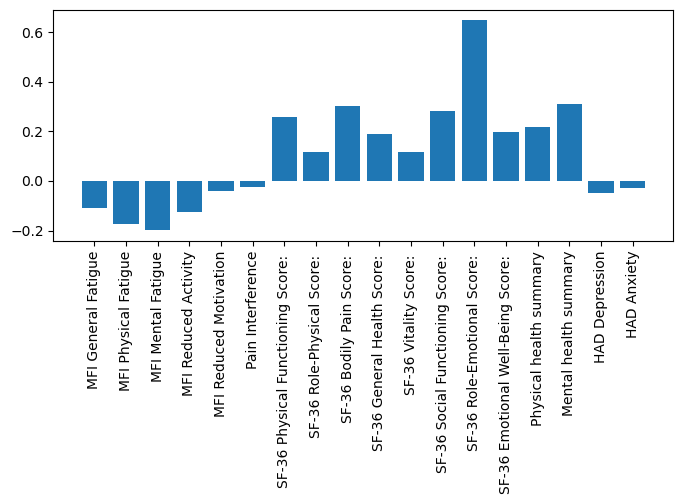

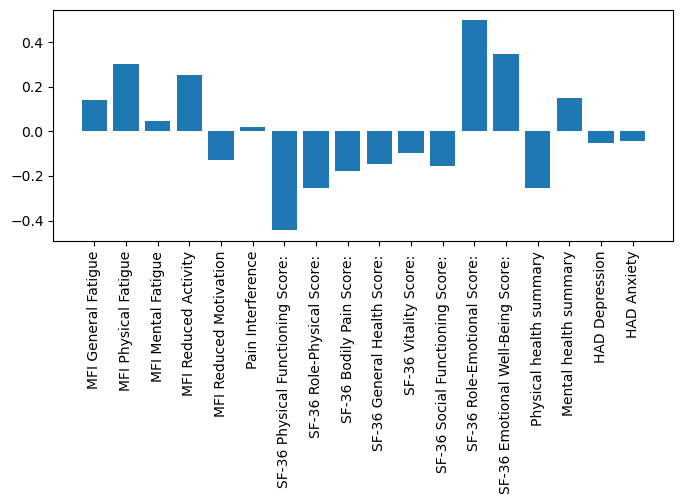

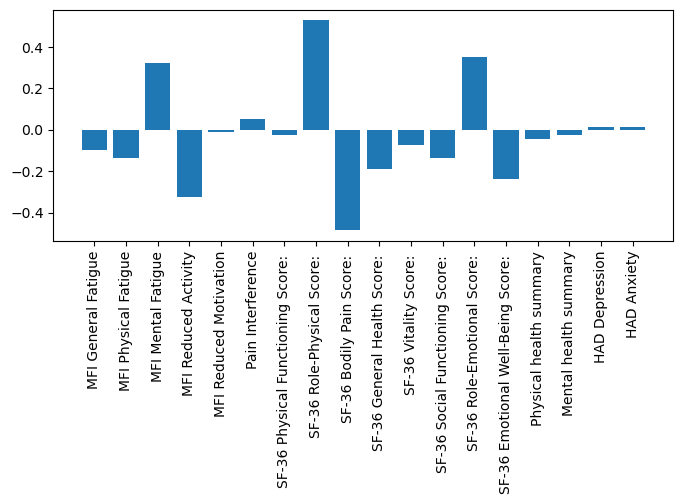

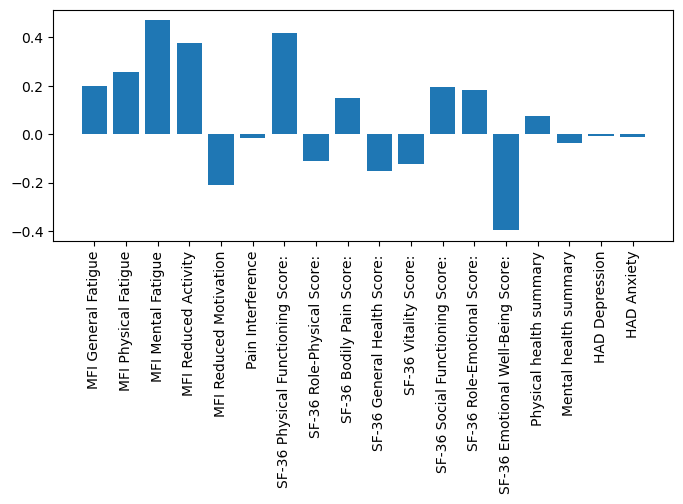

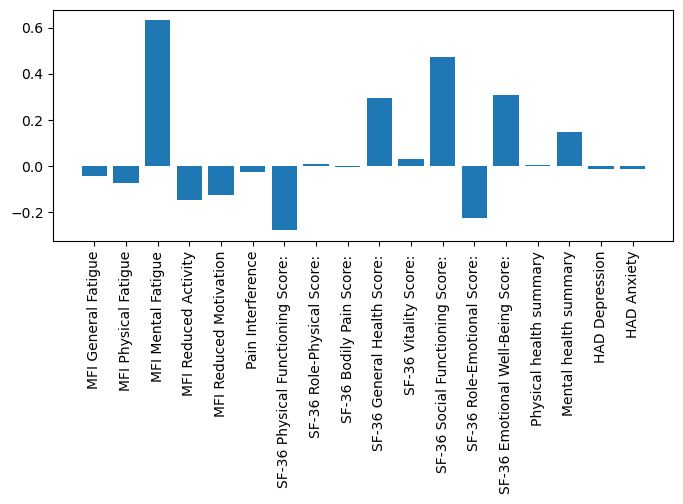

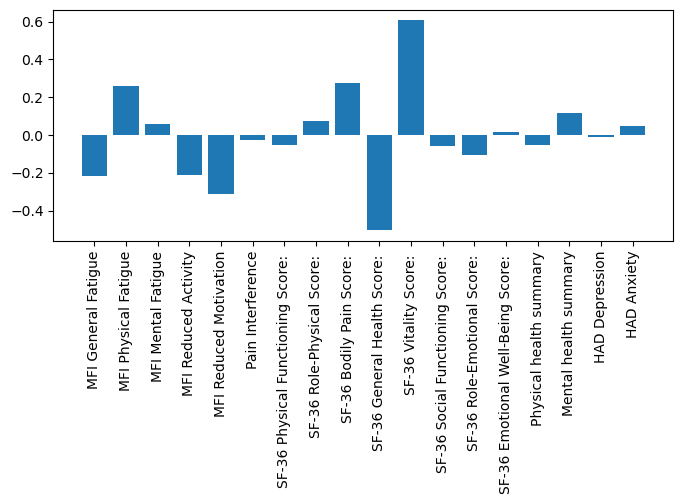

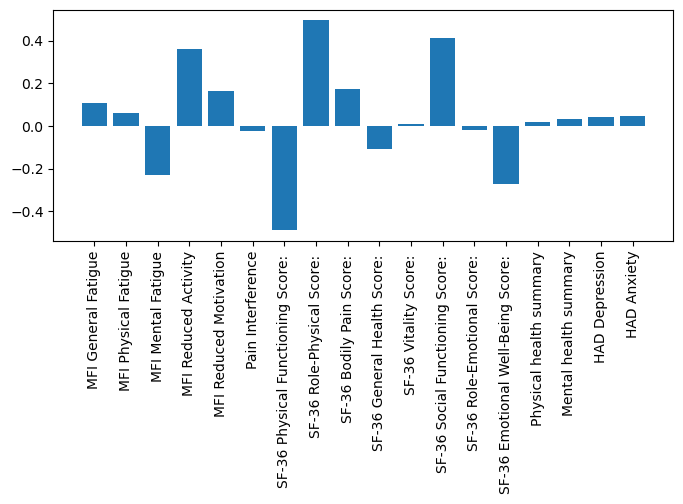

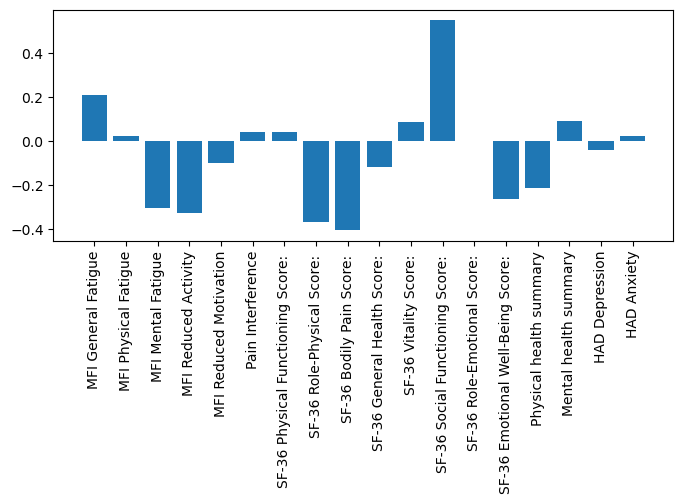

TimeoutError: [Errno 60] Operation timed out

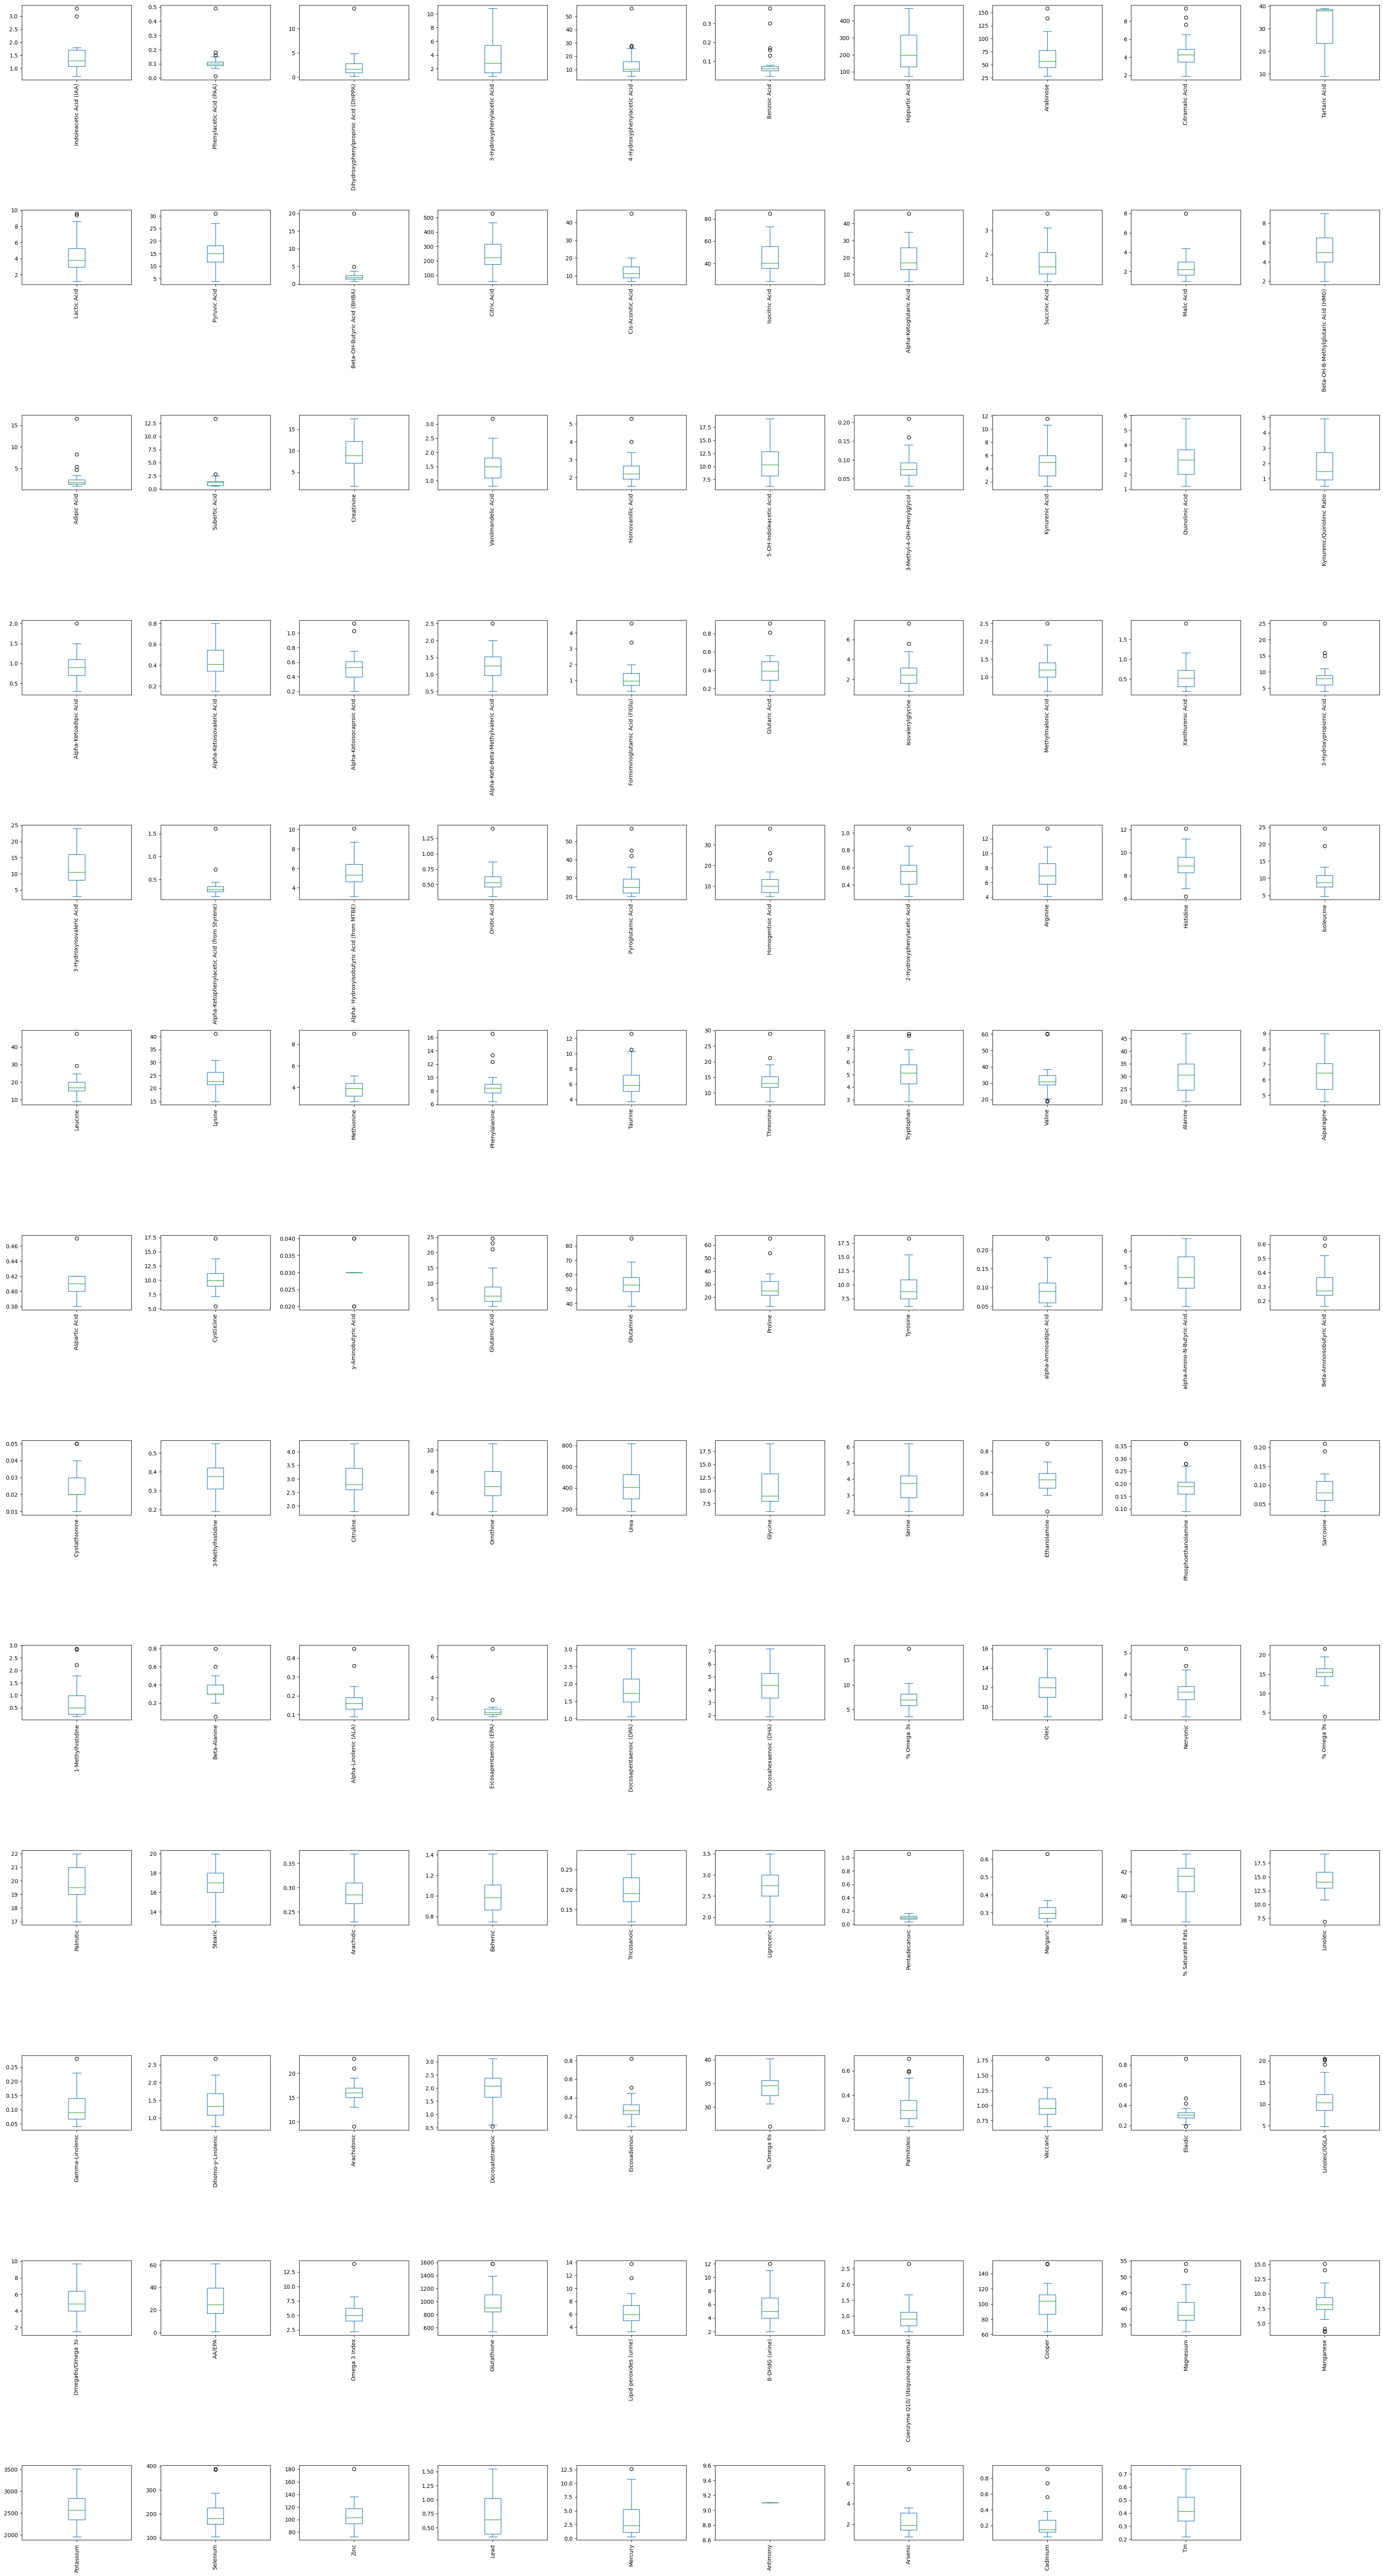

In [8]:
if MAKE_QA_PLOTS:
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.decomposition import PCA

    enrollment.plot(kind="box", subplots=True, layout=(2, 4), figsize=(15, 6))
    plt.show()

    numeric_scores = scores.select_dtypes(include="number")
    numeric_scores.plot(
        kind="box", subplots=True, layout=(3, 7), figsize=(25, 10), ylim=(-5, 105)
    )
    plt.tight_layout()
    plt.savefig("scales.pdf")
    plt.show()

    fig, ax = plt.subplots(figsize=(15, 12))
    sns.heatmap(numeric_scores.corr(method="spearman"), annot=True, ax=ax,
                cmap="vlag", vmin=-1, vmax=1)
    fig.savefig("correlation_scales.pdf", bbox_inches="tight")
    plt.show()

    pca = PCA().fit(numeric_scores)
    cumulative_variance = pca.explained_variance_ratio_.cumsum()
    fig, ax = plt.subplots(figsize=(8, 2))
    ax.plot(np.arange(1, cumulative_variance.size + 1), cumulative_variance, "o--")
    ax.set(xlabel="Number of components", ylabel="Cumulative explained variance",
           title="Explained variance by component count", ylim=(0.8, 1.01))
    ax.grid(True)
    plt.show()

    positions = np.arange(numeric_scores.shape[1])
    for component in pca.components_[:8]:
        fig, ax = plt.subplots(figsize=(8, 3))
        ax.bar(positions, component)
        ax.set_xticks(positions, numeric_scores.columns, rotation=90)
        plt.show()

    numeric_markers = nutreval_numeric.dropna(axis=1, how="all")
    marker_rows = max(1, (numeric_markers.shape[1] + 9) // 10)
    numeric_markers.plot(kind="box", subplots=True, layout=(marker_rows, 10),
                         figsize=(35, 5 * marker_rows), rot=90)
    plt.tight_layout()
    plt.savefig("boxplot_nutreval.pdf")
    plt.show()